                                                     NETFLIX AUDIENCE RATING CLASSIFICATION                                                            

In [1]:
import pandas as pd

In [2]:
ds =pd.read_csv("Dataset.csv")
ds.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print(ds.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


import libraries

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

Rating categories analysis

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


<Axes: xlabel='rating', ylabel='count'>

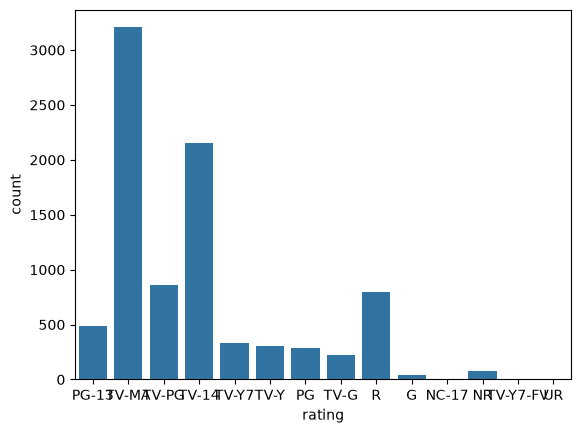

In [5]:
print(ds["rating"].value_counts())
import seaborn as sns
sns.countplot(data= ds , x= "rating")

Type and the feature selection

In [6]:
feature = ["type","country","release_year","listed_in"]
x = ds[feature]
y = ds["rating"]

Create data for training and testing

In [7]:
x_train , x_test , y_train , y_test = train_test_split(
    x,
    y,
    test_size= 0.2,
    stratify= y,
    random_state= 42
)
print("Data use for the training :", len(x_train))
print("Data use for the testing :", len(x_test))


Data use for the training : 7032
Data use for the testing : 1758


Categorical data encode

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('encoder',OneHotEncoder(handle_unknown="ignore"),
         ['type','country','listed_in','release_year'])
    ]
)

Train logistic Regression model

In [9]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
lr_model.fit(x_train, y_train)
lr_pred = lr_model.predict(x_test)
lr_accuracy = accuracy_score(y_test,lr_pred)

print("Logistic_regression accuracy", lr_accuracy)

Logistic_regression accuracy 0.5204778156996587


Train Decision Tree

In [10]:
ds_model = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])
ds_model.fit(x_train,y_train)
ds_pred  = ds_model.predict(x_test)
ds_accuracy = accuracy_score(y_test, ds_pred)
print("Decision Tree Accuracy",ds_accuracy)

Decision Tree Accuracy 0.4738339021615472


Train Random Forest

In [11]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=10,
        n_jobs=-1
    ))
])
rf_model.fit(x_train,y_train)
rf_pred = rf_model.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy",rf_accuracy)

Random Forest Accuracy 0.41865756541524457


Compare both the model

In [12]:
result = pd.DataFrame({
    "model": [
       "Logistic Regression",
       "Decision Tree",
       "Random Forest"
    ],
    "Accuracy":[
        lr_accuracy,
        ds_accuracy,
        rf_accuracy
    ]
})
print(result.sort_values(by= "Accuracy", ascending=False))
print(type(result))

                 model  Accuracy
0  Logistic Regression  0.520478
1        Decision Tree  0.473834
2        Random Forest  0.418658
<class 'pandas.core.frame.DataFrame'>


Classification Metrics

In [13]:
print("Logistic Regression Classification report :")
print(classification_report(
    y_test,
    lr_pred,
    zero_division=0
))

Logistic Regression Classification report :
              precision    recall  f1-score   support

           G       0.00      0.00      0.00         8
       NC-17       0.00      0.00      0.00         1
          NR       0.00      0.00      0.00        16
          PG       0.46      0.40      0.43        57
       PG-13       0.38      0.34      0.36        98
           R       0.50      0.51      0.50       160
       TV-14       0.49      0.51      0.50       431
        TV-G       0.00      0.00      0.00        44
       TV-MA       0.58      0.74      0.65       641
       TV-PG       0.24      0.09      0.13       172
        TV-Y       0.51      0.57      0.54        61
       TV-Y7       0.55      0.49      0.52        67
    TV-Y7-FV       0.00      0.00      0.00         1
          UR       0.00      0.00      0.00         1

    accuracy                           0.52      1758
   macro avg       0.26      0.26      0.26      1758
weighted avg       0.48      0.52   

Hyperparameter tunning

In [14]:
param_grid = {
    "classifier__C" : [0.1,1 ,10],
    "classifier__solver":["lbfgs"]
    
}
grid_search = GridSearchCV(
    lr_model,
    param_grid,
    cv=3, 
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(x_train,y_train)

print("Best parameter:",grid_search.best_params_)
print("Best CV Accuracy", grid_search.best_score_)

c:\Users\suraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Best parameter: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Best CV Accuracy 0.5285836177474402


Tuned logistic regression evaluate

In [15]:
best_model = grid_search.best_estimator_
best_pred = best_model.predict(x_test)
print("Tuned Logistic Rgression Accuracy:",accuracy_score(y_test,best_pred))
print(classification_report(y_test, best_pred,zero_division=0))

Tuned Logistic Rgression Accuracy: 0.5204778156996587
              precision    recall  f1-score   support

           G       0.00      0.00      0.00         8
       NC-17       0.00      0.00      0.00         1
          NR       0.00      0.00      0.00        16
          PG       0.46      0.40      0.43        57
       PG-13       0.38      0.34      0.36        98
           R       0.50      0.51      0.50       160
       TV-14       0.49      0.51      0.50       431
        TV-G       0.00      0.00      0.00        44
       TV-MA       0.58      0.74      0.65       641
       TV-PG       0.24      0.09      0.13       172
        TV-Y       0.51      0.57      0.54        61
       TV-Y7       0.55      0.49      0.52        67
    TV-Y7-FV       0.00      0.00      0.00         1
          UR       0.00      0.00      0.00         1

    accuracy                           0.52      1758
   macro avg       0.26      0.26      0.26      1758
weighted avg       0.48   

In [16]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",LogisticRegression(max_iter=1000))
]
)